# Baseline Model

In [1]:
! pip install facenet_pytorch --no-deps
! pip install grad-cam --no-deps
! pip install ttach --no-deps

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 15.5 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for grad-cam: filename=grad_cam-1.5.7-py3-none-any.whl size=53345 sha256=ddb52ab364dbf04dda6d90355a6dd6221d541049242bad52c578b54d507a0952
  Stored in directory: /root/.cache/pip/wheels/91/36/f0/c2367865493d51b13369769181beca14603d17d6539a5922e3
Successfully built grad-cam


## 1. IMPORTS & SETUP

In [2]:
### imports

import cv2
import matplotlib.pyplot as plt
import os, random
import numpy as np
from collections import Counter

import torch
import torch.nn as nn
from torch.utils.data import random_split
from torchvision import transforms, models
import torchvision.models as models
from torch.utils.data import Dataset, DataLoader
from torchinfo import summary
import torch.fft
import torchvision.transforms.functional as TF
from facenet_pytorch import MTCNN

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, accuracy_score
from tqdm import tqdm

## 2. CONFIGURATION & ABLATION TOGGLES

In [3]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Running on: {DEVICE.upper()}")

# Kaggle Dataset Paths
PROCESSED_PATH_MTCNN = "/input/ff-30frames-mtcnn/FF++(MTCNN)/data_mtcnn" 

# --- ABLATION CONTROL PANEL ---
# Swap these paths to test different datasets (e.g., Train on MTCNN, Test on RAW)
TRAIN_DATA_PATH = PROCESSED_PATH_MTCNN
TEST_DATA_PATH = PROCESSED_PATH_MTCNN

NUM_FRAMES = 10
BATCH_SIZE = 16
EPOCHS = 30
LR = 1e-4

classes_dict = {
    "original": 0, "DeepFakeDetection": 1, "Deepfakes": 1, 
    "Face2Face": 1, "FaceShifter": 1, "FaceSwap": 1, "NeuralTextures": 1
}

Running on: CUDA


## 3. DATASET CLASS & TRANSFORMS

In [4]:
transform = transforms.Compose([
    transforms.Resize((224, 224)), 
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class FastDeepfakeDataset(Dataset):
    def __init__(self, all_samples, allowed_primary_ids, transform=None):
        # We only keep the sample if its Primary ID is assigned to this specific split
        self.samples = [s for s in all_samples if s[3] in allowed_primary_ids]
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        folder_path, prefix, label, _ = self.samples[idx]
        frames = []
        
        for i in range(NUM_FRAMES):
            img_path = os.path.join(folder_path, f"{prefix}_frame{i}.jpg")
            if os.path.exists(img_path):
                img = Image.open(img_path).convert("RGB")
                if self.transform:
                    img = self.transform(img)
                frames.append(img)
            else:
                # Fallback to black image if a specific frame dropped
                frames.append(torch.zeros((3, 224, 224)))

        return torch.stack(frames), torch.tensor(label, dtype=torch.float32)

## 4. DATA LOADING & SPLITTING

In [5]:
def get_samples_from_path(base_path):
    samples = []
    unique_ids = set()
    for folder_name, label in classes_dict.items():
        folder_path = os.path.join(base_path, folder_name)
        if not os.path.exists(folder_path): 
            continue
        
        files = [f for f in os.listdir(folder_path) if f.endswith('_frame0.jpg')]
        for file in files:
            prefix = file.split('_frame')[0]
            primary_id = prefix.split('_')[0] 
            unique_ids.add(primary_id)
            samples.append((folder_path, prefix, label, primary_id))
    return samples, list(unique_ids)

print(f"Scanning Training Data: {TRAIN_DATA_PATH}")
train_all_samples, all_primary_ids = get_samples_from_path(TRAIN_DATA_PATH)

print(f"Scanning Testing Data: {TEST_DATA_PATH}")
test_all_samples, _ = get_samples_from_path(TEST_DATA_PATH)

# Split by Primary ID to prevent Identity Leakage
train_ids, test_ids = train_test_split(all_primary_ids, test_size=0.15, random_state=42)
train_ids, val_ids = train_test_split(train_ids, test_size=0.15, random_state=42)

# Create Datasets using the dynamic paths
train_dataset = FastDeepfakeDataset(train_all_samples, set(train_ids), transform=transform)
val_dataset = FastDeepfakeDataset(train_all_samples, set(val_ids), transform=transform)
test_dataset = FastDeepfakeDataset(test_all_samples, set(test_ids), transform=transform) # Pulls from TEST path!

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Train size: {len(train_dataset)} | Val size: {len(val_dataset)} | Test size: {len(test_dataset)}")

Scanning Training Data: /input/ff-30frames-mtcnn/FF++(MTCNN)/data_mtcnn
Scanning Testing Data: /input/ff-30frames-mtcnn/FF++(MTCNN)/data_mtcnn
Train size: 4937 | Val size: 907 | Test size: 1156


## 5. MODEL ARCHITECTURE

In [6]:
class DeepfakeModel(nn.Module):
    def __init__(self, hidden_size=256):
        super().__init__()
        
        # Using the updated weights parameter instead of pretrained=True
        self.backbone = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        self.backbone.fc = nn.Identity() # ResNet uses .fc
        feature_dim = 2048
        
        # Freeze early layers (layer1 and layer2)
        for param in self.backbone.layer1.parameters():
            param.requires_grad = False
        for param in self.backbone.layer2.parameters():
            param.requires_grad = False

        self.lstm = nn.LSTM(
            input_size=feature_dim,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )

        self.fc = nn.Linear(hidden_size * 2, 1)

    def forward(self, x):
        B, T, C, H, W = x.shape
        x = x.view(B*T, C, H, W)
        
        features = self.backbone(x)
        features = features.view(B, T, -1)

        lstm_out, _ = self.lstm(features)
        pooled_out = torch.mean(lstm_out, dim=1)
        
        out = self.fc(pooled_out)
        return out.view(-1)

model = DeepfakeModel().to(DEVICE)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 195MB/s]


## 6. LOSS, OPTIMIZER, & SCHEDULER

In [7]:
# imbalance_weight = torch.tensor([0.1667]).to(DEVICE)
# criterion = nn.BCEWithLogitsLoss(pos_weight=imbalance_weight)
criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=LR)
# scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)

summary(model, input_size=(1, NUM_FRAMES, 3, 224, 224), col_names=["input_size", "output_size", "num_params"])

Layer (type:depth-idx)                        Input Shape               Output Shape              Param #
DeepfakeModel                                 [1, 10, 3, 224, 224]      [1]                       --
├─ResNet: 1-1                                 [10, 3, 224, 224]         [10, 2048]                --
│    └─Conv2d: 2-1                            [10, 3, 224, 224]         [10, 64, 112, 112]        9,408
│    └─BatchNorm2d: 2-2                       [10, 64, 112, 112]        [10, 64, 112, 112]        128
│    └─ReLU: 2-3                              [10, 64, 112, 112]        [10, 64, 112, 112]        --
│    └─MaxPool2d: 2-4                         [10, 64, 112, 112]        [10, 64, 56, 56]          --
│    └─Sequential: 2-5                        [10, 64, 56, 56]          [10, 256, 56, 56]         --
│    │    └─Bottleneck: 3-1                   [10, 64, 56, 56]          [10, 256, 56, 56]         (75,008)
│    │    └─Bottleneck: 3-2                   [10, 256, 56, 56]         [10,

## 7. TRAINING LOOP & ADVANCED CHECKPOINTING

In [8]:
def evaluate(model, loader):
    model.eval()
    all_preds, all_labels, all_probs = [], [], []
    total_loss = 0

    with torch.no_grad():
        for videos, labels in loader:
            videos, labels = videos.to(DEVICE), labels.to(DEVICE)
            outputs = model(videos)
            loss = criterion(outputs, labels)
            total_loss += loss.item()

            probs = torch.sigmoid(outputs)
            preds = (probs > 0.5).int()

            all_probs.extend(probs.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(loader)

    acc = accuracy_score(all_labels, all_preds)
    precision = precision_score(all_labels, all_preds, zero_division=0)
    recall = recall_score(all_labels, all_preds, zero_division=0)
    f1 = f1_score(all_labels, all_preds, zero_division=0)
    auc = roc_auc_score(all_labels, all_probs)

    return avg_loss, acc, precision, recall, f1, auc


best_val_loss = float("inf")
best_count = 1 # Tracks how many times the model improves

# --- Commented Early Stopping Variables ---
# early_stopping_patience = 5
# epochs_no_improve = 0

train_metrics = {'loss': [], 'accuracy': [], 'precision': [], 'recall': [], 'f1': [], 'auc': []}
val_metrics = {'loss': [], 'accuracy': [], 'precision': [], 'recall': [], 'f1': [], 'auc': []}

for epoch in range(EPOCHS):
    model.train()
    total_loss, running_loss, running_corrects, total_samples = 0, 0.0, 0, 0
    all_preds, all_labels, all_probs = [], [], []

    pbar = tqdm(train_loader, desc=f"Training Epoch [{epoch+1}/{EPOCHS}]")

    for videos, labels in pbar:
        videos, labels = videos.to(DEVICE), labels.to(DEVICE)

        optimizer.zero_grad()
        outputs = model(videos)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        probs = torch.sigmoid(outputs)
        preds = (probs > 0.5).int()

        all_probs.extend(probs.detach().cpu().numpy())
        all_preds.extend(preds.detach().cpu().numpy())
        all_labels.extend(labels.detach().cpu().numpy())

        running_loss += loss.item() * videos.size(0)
        running_corrects += (preds == labels).sum().item()
        total_samples += labels.size(0)

        pbar.set_postfix({'loss': f'{running_loss / total_samples:.4f}', 'acc': f'{running_corrects / total_samples:.4f}'})

    # Epoch Metrics Calculation
    train_loss = total_loss / len(train_loader)
    train_acc = accuracy_score(all_labels, all_preds)
    train_prec = precision_score(all_labels, all_preds, zero_division=0)
    train_rec = recall_score(all_labels, all_preds, zero_division=0)
    train_f1 = f1_score(all_labels, all_preds, zero_division=0)
    train_auc = roc_auc_score(all_labels, all_probs)
    
    print(f"\nTrain Metrics - loss: {train_loss:.4f}, accuracy: {train_acc:.4f}, precision: {train_prec:.4f}, recall: {train_rec:.4f}, f1_score: {train_f1:.4f}, auc: {train_auc:.4f}")

    train_metrics['loss'].append(train_loss)
    train_metrics['accuracy'].append(train_acc)
    train_metrics['precision'].append(train_prec)
    train_metrics['recall'].append(train_rec)
    train_metrics['f1'].append(train_f1)
    train_metrics['auc'].append(train_auc)

    print("Validating Model...")
    val_loss, val_acc, val_prec, val_rec, val_f1, val_auc = evaluate(model, val_loader)
    
    print(f"Val Metrics - loss: {val_loss:.4f}, accuracy: {val_acc:.4f}, precision: {val_prec:.4f}, recall: {val_rec:.4f}, f1_score: {val_f1:.4f}, auc: {val_auc:.4f}")

    val_metrics['loss'].append(val_loss)
    val_metrics['accuracy'].append(val_acc)
    val_metrics['precision'].append(val_prec)
    val_metrics['recall'].append(val_rec)
    val_metrics['f1'].append(val_f1)
    val_metrics['auc'].append(val_auc)

    # --- ADVANCED CHECKPOINT SAVING & EARLY STOPPING LOGIC ---
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), f"best_model_{best_count}.pth")
        torch.save(model.state_dict(), "best_model.pth") # Master copy
        print(f"Best model saved! (best_model_{best_count}.pth)")
        best_count += 1
        
        # COMMENTED EARLY STOPPING RESET
        # epochs_no_improve = 0 
    # else:
        # epochs_no_improve += 1
        # print(f"Validation loss did not improve. Strike {epochs_no_improve}/{early_stopping_patience}")

    # Foe adaptive LR
    # scheduler.step(val_loss)

    # Save Explicit Milestones
    if (epoch + 1) in [10, 20, 30]:
        torch.save(model.state_dict(), f"model_epoch_{epoch+1}.pth")
        print(f"-> Milestone reached! Saved model_epoch_{epoch+1}.pth")

    # COMMENTED EARLY STOPPING BREAK
    # if epochs_no_improve >= early_stopping_patience:
    #     print("\nEarly stopping triggered! The model stopped learning.")
    #     print("Restoring the best weights...")
    #     model.load_state_dict(torch.load("best_model.pth"))
    #     break

    # Old LR Early Stopping Logic 
    current_lr = optimizer.param_groups[0]["lr"]
    # COMMENTED
    # if current_lr < 1e-6: # if the learning rate drops too low, the model is stuck
    #     print("Early stopping triggered: Learning rate dropped too low.")
    #     break

    print(f"Epoch {epoch+1}/{EPOCHS} — ValLoss: {val_loss:.4f} — LR: {current_lr:.6f}\n")

# Save final state regardless of performance
torch.save(model.state_dict(), "model_final.pth")
print("\nTraining Complete! Final epoch saved as model_final.pth")

Training Epoch [1/30]: 100%|██████████| 309/309 [48:57<00:00,  9.51s/it, loss=0.3422, acc=0.8617]


Train Metrics - loss: 0.3424, accuracy: 0.8617, precision: 0.8690, recall: 0.9865, f1_score: 0.9240, auc: 0.7921
Validating Model...


Val Metrics - loss: 0.2273, accuracy: 0.9118, precision: 0.9119, recall: 0.9936, f1_score: 0.9510, auc: 0.9315
Best model saved! (best_model_1.pth)
Epoch 1/30 — ValLoss: 0.2273 — LR: 0.000100



Training Epoch [2/30]: 100%|██████████| 309/309 [08:09<00:00,  1.58s/it, loss=0.2065, acc=0.9178]


Train Metrics - loss: 0.2065, accuracy: 0.9178, precision: 0.9383, recall: 0.9672, f1_score: 0.9525, auc: 0.9406
Validating Model...


Val Metrics - loss: 0.1745, accuracy: 0.9338, precision: 0.9604, recall: 0.9629, f1_score: 0.9616, auc: 0.9562
Best model saved! (best_model_2.pth)
Epoch 2/30 — ValLoss: 0.1745 — LR: 0.000100



... (80 outputs left out)

Val Metrics - loss: 0.2649, accuracy: 0.9405, precision: 0.9471, recall: 0.9859, f1_score: 0.9661, auc: 0.9743
Epoch 29/30 — ValLoss: 0.2649 — LR: 0.000100



Training Epoch [30/30]: 100%|██████████| 309/309 [08:09<00:00,  1.58s/it, loss=0.0180, acc=0.9941]


Train Metrics - loss: 0.0179, accuracy: 0.9941, precision: 0.9962, recall: 0.9969, f1_score: 0.9966, auc: 0.9995
Validating Model...


Val Metrics - loss: 0.1962, accuracy: 0.9438, precision: 0.9716, recall: 0.9629, f1_score: 0.9672, auc: 0.9792
-> Milestone reached! Saved model_epoch_30.pth
Epoch 30/30 — ValLoss: 0.1962 — LR: 0.000100


Training Complete! Final epoch saved as model_final.pth


## 8. CONSOLIDATED EVALUATION & VISUALIZATION


Saving Training History Plots...


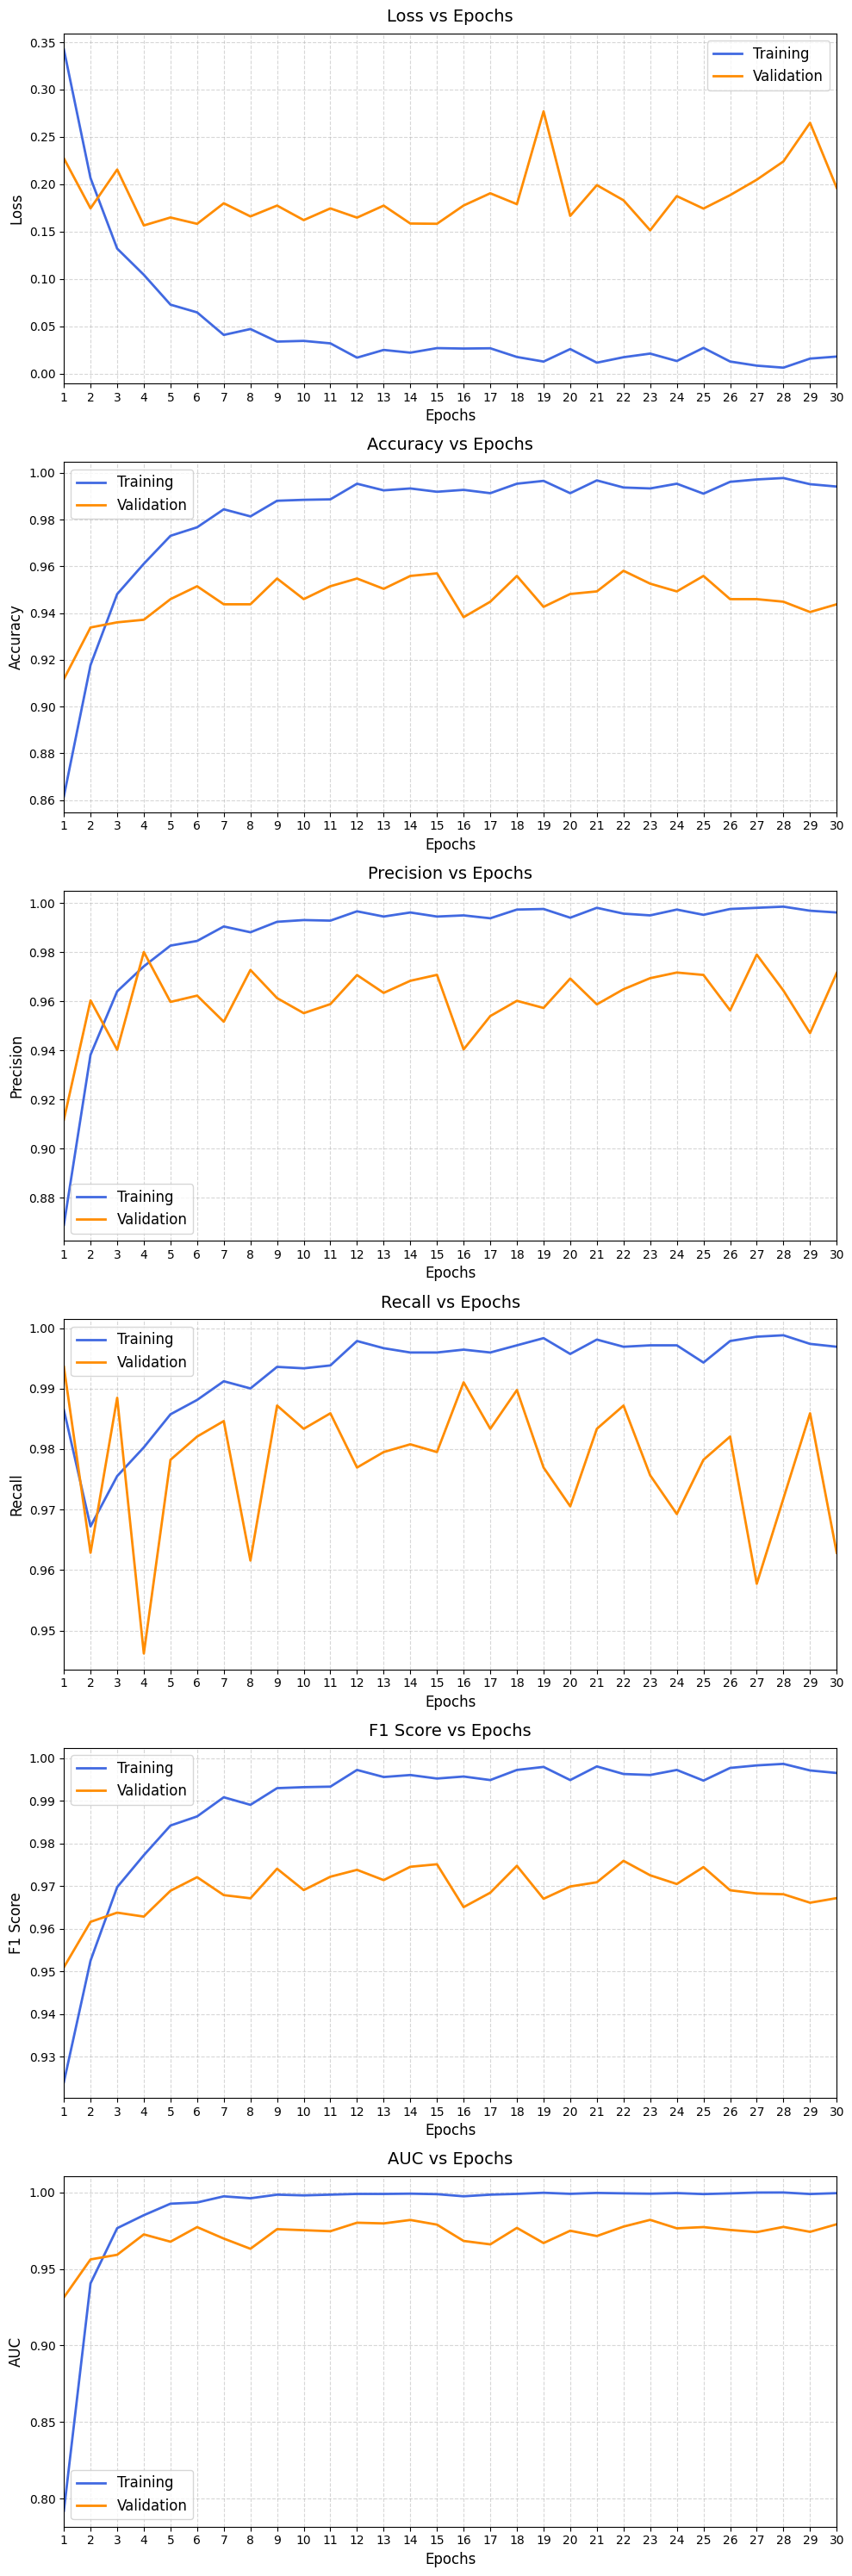


--------------------------------------------------
Evaluating 'best_model.pth'
--------------------------------------------------


Testing best_model.pth: 100%|██████████| 73/73 [14:58<00:00, 12.31s/it]



--- CLASSIFICATION REPORT ---
                 precision    recall  f1-score   support

Original (Real)     0.8889    0.7568    0.8175       148
Deepfake (Fake)     0.9650    0.9861    0.9755      1008

       accuracy                         0.9567      1156
      macro avg     0.9270    0.8714    0.8965      1156
   weighted avg     0.9553    0.9567    0.9552      1156

------------------------------
There were 50 errors in 1156 tests for an accuracy of  95.67%


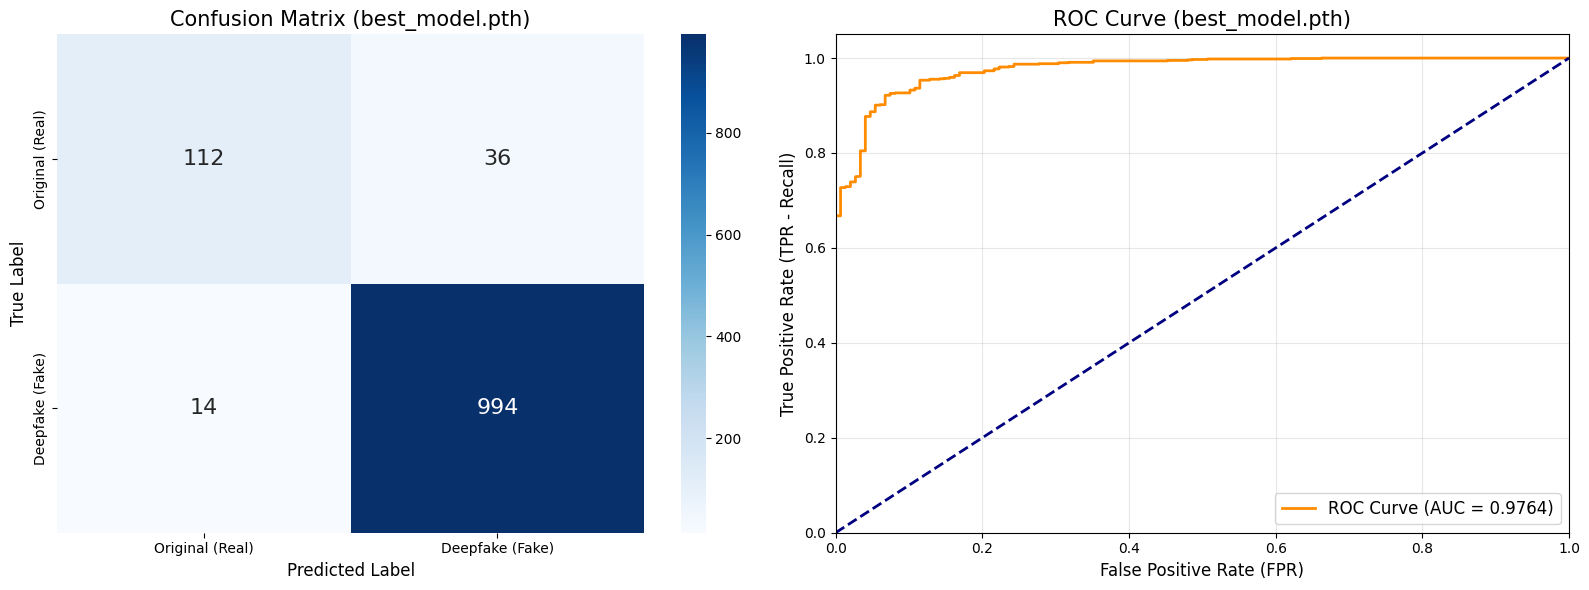


--------------------------------------------------
Evaluating 'model_epoch_10.pth'
--------------------------------------------------


Testing model_epoch_10.pth: 100%|██████████| 73/73 [00:45<00:00,  1.62it/s]



--- CLASSIFICATION REPORT ---
                 precision    recall  f1-score   support

Original (Real)     0.8818    0.6554    0.7519       148
Deepfake (Fake)     0.9512    0.9871    0.9688      1008

       accuracy                         0.9446      1156
      macro avg     0.9165    0.8213    0.8604      1156
   weighted avg     0.9424    0.9446    0.9411      1156

------------------------------
There were 64 errors in 1156 tests for an accuracy of  94.46%


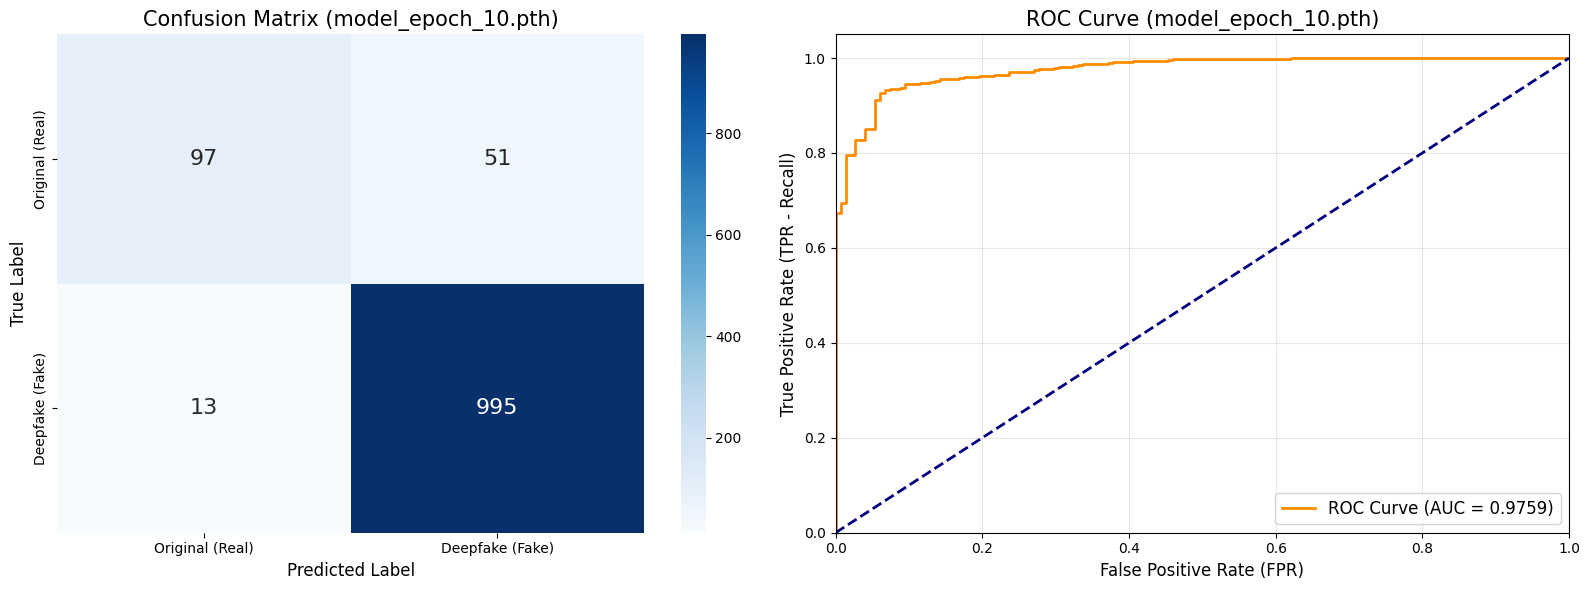


--------------------------------------------------
Evaluating 'model_epoch_20.pth'
--------------------------------------------------


Testing model_epoch_20.pth: 100%|██████████| 73/73 [00:42<00:00,  1.70it/s]



--- CLASSIFICATION REPORT ---
                 precision    recall  f1-score   support

Original (Real)     0.8116    0.7568    0.7832       148
Deepfake (Fake)     0.9646    0.9742    0.9694      1008

       accuracy                         0.9464      1156
      macro avg     0.8881    0.8655    0.8763      1156
   weighted avg     0.9450    0.9464    0.9456      1156

------------------------------
There were 62 errors in 1156 tests for an accuracy of  94.64%


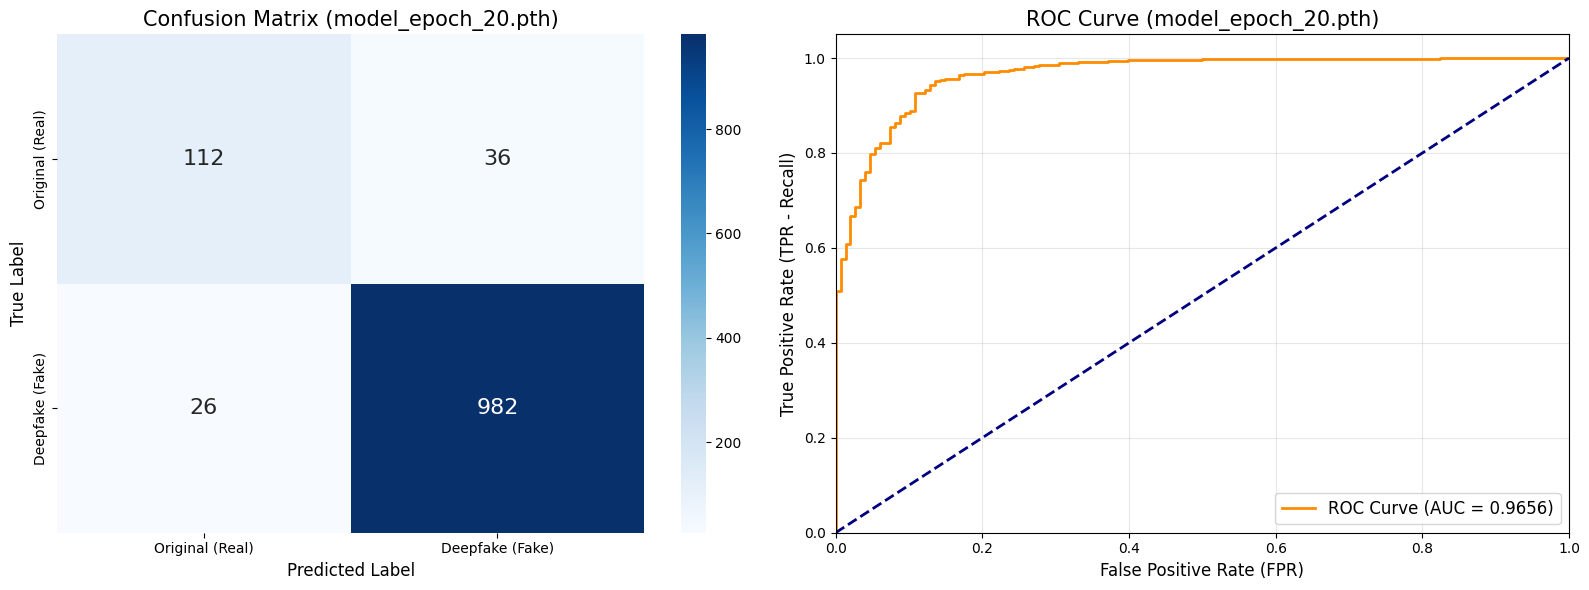


--------------------------------------------------
Evaluating 'model_epoch_30.pth'
--------------------------------------------------


Testing model_epoch_30.pth: 100%|██████████| 73/73 [00:43<00:00,  1.69it/s]



--- CLASSIFICATION REPORT ---
                 precision    recall  f1-score   support

Original (Real)     0.7834    0.8311    0.8066       148
Deepfake (Fake)     0.9750    0.9663    0.9706      1008

       accuracy                         0.9490      1156
      macro avg     0.8792    0.8987    0.8886      1156
   weighted avg     0.9505    0.9490    0.9496      1156

------------------------------
There were 59 errors in 1156 tests for an accuracy of  94.90%


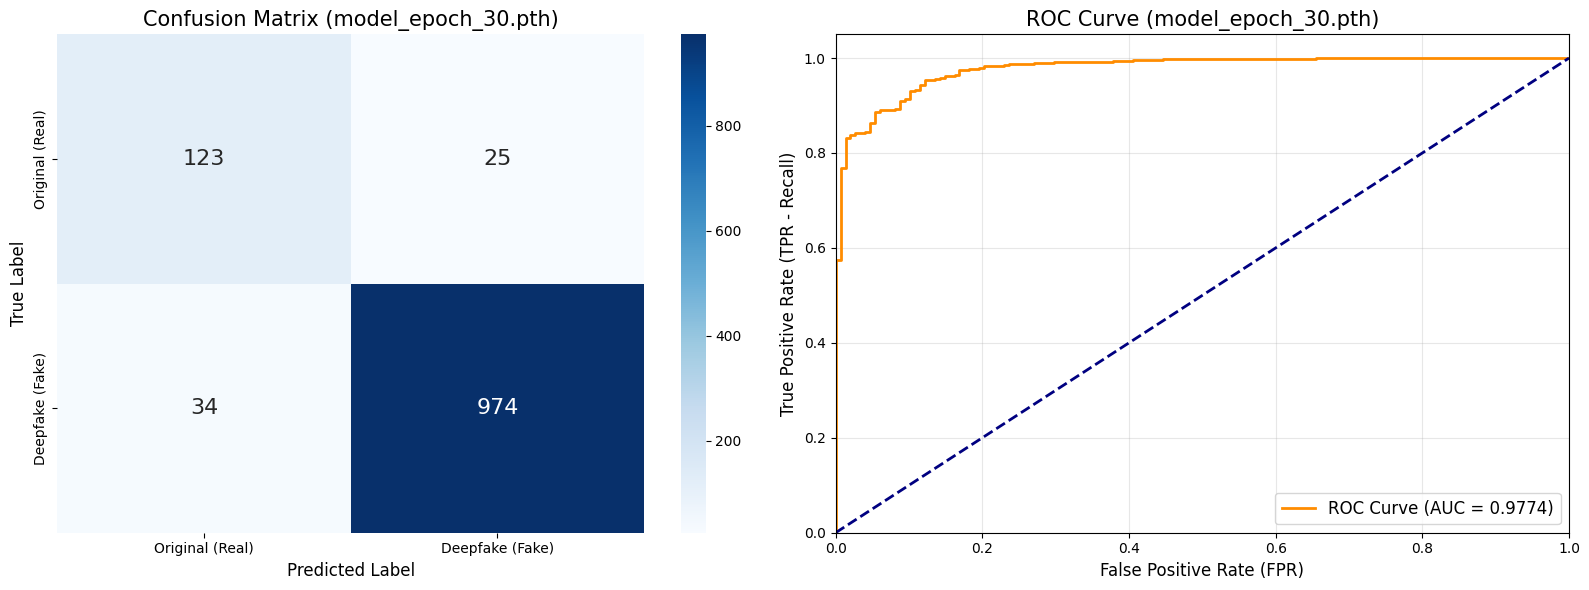


--------------------------------------------------
Evaluating 'model_final.pth'
--------------------------------------------------


Testing model_final.pth: 100%|██████████| 73/73 [00:43<00:00,  1.69it/s]



--- CLASSIFICATION REPORT ---
                 precision    recall  f1-score   support

Original (Real)     0.7834    0.8311    0.8066       148
Deepfake (Fake)     0.9750    0.9663    0.9706      1008

       accuracy                         0.9490      1156
      macro avg     0.8792    0.8987    0.8886      1156
   weighted avg     0.9505    0.9490    0.9496      1156

------------------------------
There were 59 errors in 1156 tests for an accuracy of  94.90%


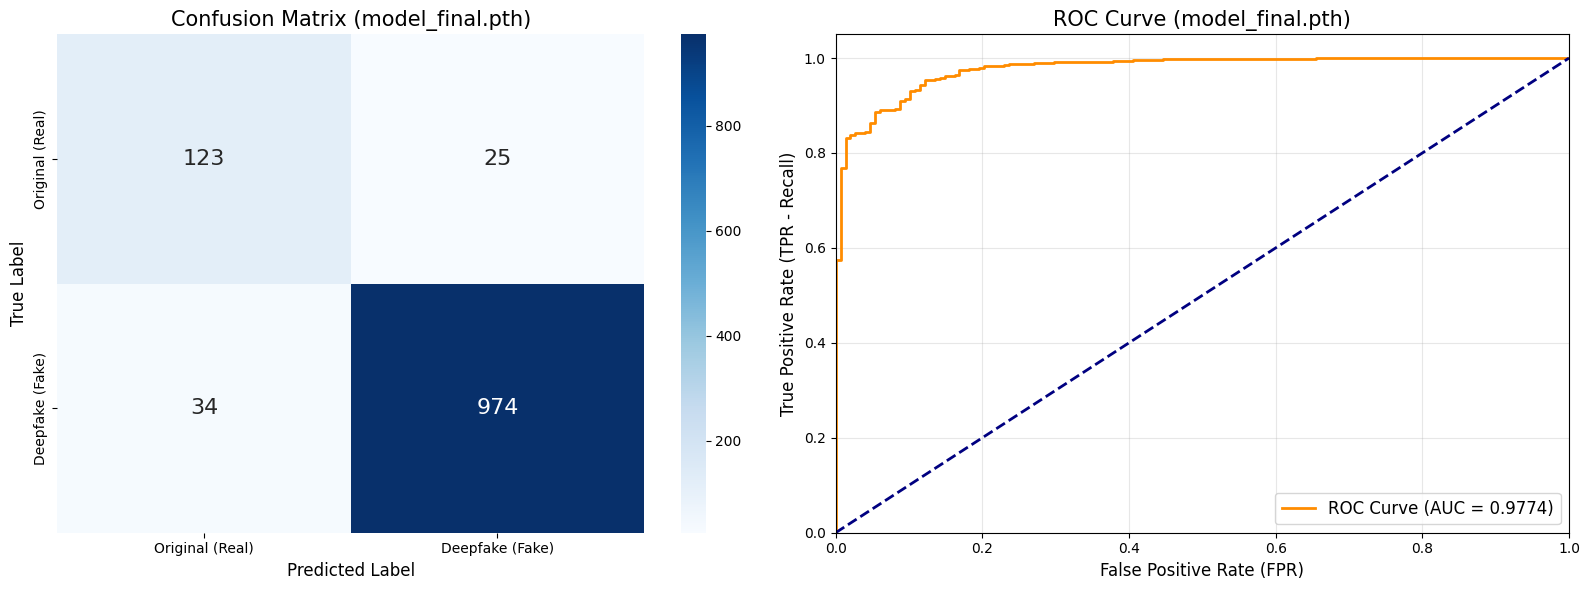


Zipping all models, reports, and plots for export...
-> ablation_results_export.zip created successfully!
Done! You can now download your complete ablation package from the Kaggle working directory.


In [9]:
import os
import shutil
import math
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc, classification_report, accuracy_score
from tqdm import tqdm

OUTPUT_DIR = "/kaggle/working/experiment_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ---------------------------------------------------------
# 1. Plot & Save Training History (Loss, Acc, Precision, Recall, F1, AUC)
# ---------------------------------------------------------
def plot_metrics(train_history, val_history, metric_names):
    num_metrics = len(metric_names)
    num_epochs = len(train_history[metric_names[0]])

    fig, axes = plt.subplots(num_metrics, 1, figsize=(10, 5 * num_metrics))
    if num_metrics == 1: axes = [axes]
    rng = range(1, num_epochs + 1)

    for ax, metric_name in zip(axes, metric_names):
        ax.plot(rng, train_history[metric_name], label="Training", linewidth=2, color='royalblue')
        ax.plot(rng, val_history[metric_name], label="Validation", linewidth=2, color='darkorange')
        ax.legend(fontsize=12)
        ax.set_xlabel("Epochs", fontsize=12)
        
        if metric_name == "auc":
            ax.set_ylabel("AUC", fontsize=12)
            ax.set_title("AUC vs Epochs", fontsize=14, pad=10)
        elif metric_name == "f1":
            ax.set_ylabel("F1 Score", fontsize=12)
            ax.set_title("F1 Score vs Epochs", fontsize=14, pad=10)
        else:
            ax.set_ylabel(metric_name.capitalize(), fontsize=12)
            ax.set_title(f"{metric_name.capitalize()} vs Epochs", fontsize=14, pad=10)
            
        ax.grid(True, linestyle='--', alpha=0.5)
        ax.set_xlim(1, num_epochs)
        ax.set_xticks(rng)

    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "training_history_plots.png"), dpi=300)
    plt.show()

print("\nSaving Training History Plots...")
# Using the dictionaries you populated during the training loop
metrics_to_plot = ['loss', 'accuracy', 'precision', 'recall', 'f1', 'auc']
plot_metrics(train_metrics, val_metrics, metrics_to_plot)

# ---------------------------------------------------------
# 2. Automated Evaluation for All Checkpoints
# ---------------------------------------------------------
CLASSES = ['Original (Real)', 'Deepfake (Fake)']

# List of models we want to evaluate
models_to_test = [
    "best_model.pth", 
    "model_epoch_10.pth", 
    "model_epoch_20.pth", 
    "model_epoch_30.pth", 
    "model_final.pth"
]

for model_name in models_to_test:
    if not os.path.exists(model_name):
        continue
        
    print(f"\n{'-'*50}\nEvaluating '{model_name}'\n{'-'*50}")
    model.load_state_dict(torch.load(model_name))
    model.eval()

    all_preds, all_labels, all_probs = [], [], []

    with torch.no_grad():
        for videos, labels in tqdm(test_loader, desc=f"Testing {model_name}"):
            videos, labels = videos.to(DEVICE), labels.to(DEVICE)
            outputs = model(videos)

            probs = torch.sigmoid(outputs)
            preds = (probs > 0.5).int()

            all_probs.extend(probs.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    # Generate and Save Classification Report
    true_labels = np.array(all_labels).astype(int)
    predicted_labels = np.array(all_preds).astype(int)
    
    report_str = classification_report(true_labels, predicted_labels, target_names=CLASSES, digits=4)
    accuracy = accuracy_score(true_labels, predicted_labels)
    num_errors = np.sum(true_labels != predicted_labels)
    
    report_header = f"Results for {model_name}\nAccuracy: {accuracy * 100:.2f}%\nErrors: {num_errors} out of {len(all_preds)}\n\n"
    
    print("\n--- CLASSIFICATION REPORT ---")
    print(report_str)
    print("-" * 30)
    print(f'There were {num_errors} errors in {len(predicted_labels)} tests for an accuracy of {accuracy * 100:6.2f}%')
    
    # Save text report to disk
    report_filename = os.path.join(OUTPUT_DIR, f"report_{model_name.replace('.pth', '.txt')}")
    with open(report_filename, "w") as f:
        f.write(report_header + report_str)

    # Generate and Save Plots (Confusion Matrix & ROC)
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Confusion Matrix
    cm = confusion_matrix(true_labels, predicted_labels)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
                xticklabels=CLASSES, yticklabels=CLASSES, annot_kws={"size": 16})
    axes[0].set_title(f'Confusion Matrix ({model_name})', fontsize=15)
    axes[0].set_xlabel('Predicted Label', fontsize=12)
    axes[0].set_ylabel('True Label', fontsize=12)

    # ROC Curve
    fpr, tpr, _ = roc_curve(true_labels, all_probs)
    roc_auc = auc(fpr, tpr)
    axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.4f})')
    axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    axes[1].set_xlim([0.0, 1.0])
    axes[1].set_ylim([0.0, 1.05])
    axes[1].set_xlabel('False Positive Rate (FPR)', fontsize=12)
    axes[1].set_ylabel('True Positive Rate (TPR - Recall)', fontsize=12)
    axes[1].set_title(f'ROC Curve ({model_name})', fontsize=15)
    axes[1].legend(loc="lower right", fontsize=12)
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    
    # Save image to disk and display it
    plot_filename = os.path.join(OUTPUT_DIR, f"plots_{model_name.replace('.pth', '.png')}")
    plt.savefig(plot_filename, dpi=300)
    plt.show() 

    # Move the model weights into the output directory so they get zipped too
    shutil.copy(model_name, os.path.join(OUTPUT_DIR, model_name))

# ---------------------------------------------------------
# 3. Zip Everything for Easy Download
# ---------------------------------------------------------
print("\nZipping all models, reports, and plots for export...")
shutil.make_archive('/kaggle/working/ablation_results_export', 'zip', OUTPUT_DIR)
print("-> ablation_results_export.zip created successfully!")
print("Done! You can now download your complete ablation package from the Kaggle working directory.")